# Week 5

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import math
import pickle

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

!pip install tqdm
from tqdm.auto import tqdm

In [2]:
%%script true # Skips the cell to prevent repeated dataset downloads.

data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data

In [3]:
df_raw = pd.read_csv('course_lead_scoring_2026.csv')

In [4]:
df = df_raw.copy()
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


## Data Preparation

In [5]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
categorical_features = list(df.dtypes[df.dtypes == 'str'].index)
categorical_features

['lead_source', 'industry', 'employment_status', 'location']

In [8]:
numerical_features = list(df.dtypes[(df.dtypes != 'str') & (df.dtypes.index != 'converted')].index)
numerical_features

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [9]:
df[categorical_features] = df[categorical_features].fillna('NA')

df[numerical_features] = df[numerical_features].fillna(0.0)

In [10]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### Data Split

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

In [12]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [13]:
del df_train['converted']
del df_val['converted']

## Question 1

In [14]:
df_train[numerical_features]

,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,80198.0,5,9,0.91
1,50548.0,2,5,0.48
2,76300.0,0,3,0.42
3,80371.0,2,6,0.49
4,73567.0,2,4,0.48
...,...,...,...,...
2995,84573.0,2,3,0.37
2996,85051.0,1,3,0.56
2997,21561.0,0,1,0.17
2998,31691.0,3,5,0.49


In [15]:
auc_scores = {}

for col in numerical_features:
    auc= roc_auc_score(y_train, df_train[col])
    auc_scores[col] = auc

print(auc_scores)

{'annual_income': 0.6081977776250831, 'number_of_courses_viewed': 0.7229894623989618, 'interaction_count': 0.7649203047563227, 'lead_score': 0.7882254810906102}


In [16]:
df_auc = pd.DataFrame(
    auc_scores.items(), columns = ['numerical_feature', 'auc_score']
    ).sort_values(by='auc_score', ascending=False).reset_index(drop=True)

df_auc

,numerical_feature,auc_score
0,lead_score,0.788225
1,interaction_count,0.764920
2,number_of_courses_viewed,0.722989
3,annual_income,0.608198


In [17]:
best_auc= df_auc.loc[df_auc['auc_score'].idxmax(), 'numerical_feature']

print(f"The numerical feature with the best ROC-AUC score is {best_auc}.")

The numerical feature with the best ROC-AUC score is lead_score.


## Question 2

#### Applying One-Hot Encoding

In [18]:
def one_hot_encoding(df, dv=None):
    data_dict = df.to_dict(orient='records')

    if dv is None:
        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(data_dict)
    else:
        X_train = dv.transform(data_dict)

    return X_train, dv

In [19]:
X_train, dv = one_hot_encoding(df_train)

#### Training The Model

In [20]:
def model_train(X_train, y_train, C):
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    return model

In [21]:
model = model_train(X_train, y_train, 1.0)

#### Validation

In [22]:
X_val, _ = one_hot_encoding(df_val, dv)

In [23]:
y_pred = model.predict_proba(X_val)[:, 1]

#### AUC

In [24]:
auc= round(roc_auc_score(y_val, y_pred), 3)
print(f"The AUC for this model on the validation dataset is {auc}.")

The AUC for this model on the validation dataset is 0.732.


## Question 3

In [25]:
# Generating threshold from 0.0 t0 1.0 with step 0.01.

thresholds = np.arange(0.0, 1.01, 0.01).tolist()

In [26]:
results = {}

for t in thresholds:
    tp = ((y_pred >= t) & (y_val == 1)).sum()
    fp = ((y_pred >= t) & (y_val == 0)).sum()
    fn = ((y_pred < t) & (y_val == 1)).sum()
    tn = ((y_pred < t) & (y_val == 0)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    results[t] = precision, recall

df_thresholds = pd.DataFrame([(t, p, r) for t, (p, r) in results.items()],
                            columns=['threshold', 'precision', 'recall']
)
df_thresholds

,threshold,precision,recall
0,0.00,0.586,1.000000
1,0.01,0.586,1.000000
2,0.02,0.586,1.000000
3,0.03,0.586,1.000000
4,0.04,0.586,1.000000
...,...,...,...
96,0.96,1.000,0.001706
97,0.97,0.000,0.000000
98,0.98,0.000,0.000000
99,0.99,0.000,0.000000


In [27]:
df_pr = df_thresholds[
    ~((df_thresholds['precision'] == 0) & (df_thresholds['recall'] == 0))
]

df_pr['difference'] = (
    df_pr['precision'] - df_pr['recall']
).abs()

intersection = df_pr.loc[df_pr['difference'].idxmin()]

print(f"Threshold: {intersection['threshold']:.2f}")
print(f"Precision: {intersection['precision']:.3f}")
print(f"Recall: {intersection['recall']:.3f}")

Threshold: 0.63
Precision: 0.733
Recall: 0.725


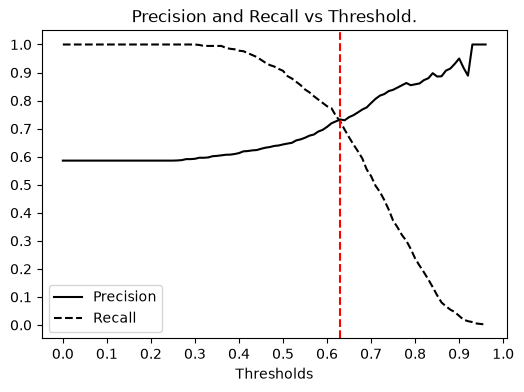

In [28]:
plt.figure(figsize=(6, 4))

plt.plot(df_pr.threshold, df_pr.precision, color='black', linestyle='solid', label='Precision')
plt.plot(df_pr.threshold, df_pr.recall, color='black', linestyle='dashed', label='Recall')
plt.legend()

plt.axvline(
    intersection['threshold'],
    color='red',
    linestyle='--',
    label='Closest intersection'
)

plt.xticks(np.linspace(0, 1, 11))
plt.yticks(np.linspace(0, 1, 11))

plt.xlabel('Thresholds')
plt.title('Precision and Recall vs Threshold.')

# plt.savefig('04_fpr_tpr_plot.svg')

plt.show()

## Question 4

In [29]:
df_f1 = df_thresholds.copy()
df_f1.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


In [30]:
df_f1['f1'] = (
    2 * df_f1['precision'] * df_f1['recall']/
    (df_f1['precision'] + df_f1['recall'])
).fillna(0)

maximal = df_f1.loc[df_f1['f1'].idxmax()]

In [31]:
maximal

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

## Question 5

In [32]:
def train(df, y, C=1.0):
    cat = df[categorical_features + numerical_features].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(cat)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)

    return dv, model

In [33]:
def predict(df, dv, model):
    cat = df[categorical_features + numerical_features].to_dict(orient='records')
    
    X = dv.transform(cat)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [34]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [35]:
aucs = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
    df_train = df_full_train.iloc[train_idx]
    y_train = df_train.converted.values

    df_val = df_full_train.iloc[val_idx]
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    rocauc = roc_auc_score(y_val, y_pred)
    aucs.append(rocauc)

0it [00:00, ?it/s]

In [36]:
np.array(aucs).round(3)

array([0.731, 0.73 , 0.736, 0.741, 0.721])

In [37]:
print('auc = %0.3f ± %0.3f' % (np.mean(aucs), np.std(aucs)))

auc = 0.732 ± 0.007


## Question 6

In [38]:
c = [0.000001, 0.001, 1]

In [39]:
nfolds= 5
kfold = KFold(n_splits=nfolds, shuffle=True, random_state=1)

In [40]:
for i in c:
    aucs = []

    for train_idx, val_idx in tqdm(kfold.split(df_full_train)):
        df_train = df_full_train.iloc[train_idx]
        y_train = df_train.converted.values
    
        df_val = df_full_train.iloc[val_idx]
        y_val = df_val.converted.values
    
        dv, model = train(df_train, y_train, C=i)
        y_pred = predict(df_val, dv, model)
    
        rocauc = roc_auc_score(y_val, y_pred)
        aucs.append(rocauc)
    print('C=%s, auc = %0.3f ± %0.3f' % (i, np.mean(aucs), np.std(aucs)))

0it [00:00, ?it/s]

C=1e-06, auc = 0.617 ± 0.019


0it [00:00, ?it/s]

C=0.001, auc = 0.749 ± 0.010


0it [00:00, ?it/s]

C=1, auc = 0.732 ± 0.007


## Training The Model (Deployment Exercise)

In [59]:
c = 0.001

In [60]:
y_train = df_full_train.converted.values

In [61]:
dv_deploy, model_deploy = train(df_full_train, y_train, C=c)

In [62]:
y_pred = predict(df_test, dv_deploy, model_deploy)

In [63]:
auc_deploy= round(roc_auc_score(y_test, y_pred), 3)
print(f"The AUC for this model on the validation dataset is {auc_deploy}.")

The AUC for this model on the validation dataset is 0.738.


In [71]:
t = 0.5
tp = ((y_pred >= t) & (y_test == 1)).sum()
fp = ((y_pred >= t) & (y_test == 0)).sum()
fn = ((y_pred < t) & (y_test == 1)).sum()
tn = ((y_pred < t) & (y_test == 0)).sum()
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
print(f"Precision: {precision}.")
print()
print(f"Recall: {recall}.")


Precision: 0.6269554753309265.

Recall: 0.9172535211267606.


In [7]:
output_file = 'model.bin'

In [ ]:
%%script true

# f_out = open(output_file, 'wb')
# pickle.dump((dv_deploy, model_deploy), f_out)
# f_out.close()

# f_in = open(output_file, 'rb')
# dv, model = pickle.load(f_in)
# f_in.close()

In [9]:
# Saving the model.

# with open(output_file, 'wb') as model_file:
    # pickle.dump((dv_deploy, model_deploy), model_file)

In [10]:
# Loading the model.

with open(output_file, 'rb') as model_file:
    (dv_deploy, model_deploy) = pickle.load(model_file)

In [11]:
dv_deploy

DictVectorizer(sparse=False)

In [12]:
model_deploy

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.001
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net pena